# MLP

## Notes
- The files have already been split into training, validation, and testing sets:
  - `train_ecg.ipynb`
  - `validation_ecg.ipynb`
  - `testing_ecg.ipynb` (not yet provided)
  - In-notebook partitioning, `train_test_split()`, is not needed.

## File Conversion

### Imports

In [1]:
# General Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# Load the metadata
META_raw         = pd.read_csv('train_metadata.csv')
META_raw.columns = META_raw.columns.str.strip() # Drops leading/trailing whitespace in column names
META_raw         = META_raw.replace("NA", np.nan)
META = META_raw.dropna()

In [3]:
# Load the ECG
TRAIN_ECG  = np.load('train_ecg.npz')
TRAIN_ECGx = TRAIN_ECG['X']
TRAIN_ECGy = TRAIN_ECG['y']

VALID_ECG  = np.load('validation_ecg.npz')
VALID_ECGx = VALID_ECG['X']
VALID_ECGy = VALID_ECG['y']

# Convert the dictionary-like npz contents into a Pandas DataFrame
# Assumes arrays have the same lengths/shapes
df_train = pd.DataFrame(TRAIN_ECGx, columns=[f'x_{i+1}' for i in range(TRAIN_ECGx.shape[1])])
df_train['target'] = TRAIN_ECGy

df_valid = pd.DataFrame(VALID_ECGx, columns=[f'x_{i+1}' for i in range(VALID_ECGx.shape[1])])
df_valid['target'] = VALID_ECGy

In [4]:
df_train.head()

,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,x_10,...,x_244,x_245,x_246,x_247,x_248,x_249,x_250,x_251,x_252,target
0,-0.305,-0.310,-0.300,-0.305,-0.290,-0.300,-0.300,-0.305,-0.305,-0.290,...,-0.300,-0.315,-0.315,-0.315,-0.330,-0.315,-0.320,-0.315,-0.325,0
1,-0.330,-0.345,-0.345,-0.355,-0.350,-0.340,-0.330,-0.340,-0.340,-0.340,...,-0.360,-0.350,-0.350,-0.355,-0.360,-0.355,-0.365,-0.355,-0.350,0
2,-0.375,-0.385,-0.355,-0.360,-0.355,-0.360,-0.360,-0.370,-0.360,-0.345,...,-0.320,-0.315,-0.325,-0.335,-0.330,-0.315,-0.320,-0.320,-0.330,0
3,-0.345,-0.345,-0.350,-0.355,-0.345,-0.330,-0.330,-0.335,-0.335,-0.340,...,-0.340,-0.325,-0.325,-0.320,-0.315,-0.335,-0.335,-0.345,-0.335,0
4,-0.340,-0.340,-0.340,-0.325,-0.325,-0.325,-0.345,-0.350,-0.340,-0.330,...,-0.295,-0.300,-0.305,-0.310,-0.325,-0.325,-0.315,-0.310,-0.315,0


In [5]:
df_valid.head()

,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,x_10,...,x_244,x_245,x_246,x_247,x_248,x_249,x_250,x_251,x_252,target
0,-0.345,-0.345,-0.350,-0.360,-0.355,-0.345,-0.365,-0.395,-0.400,-0.395,...,-0.255,-0.250,-0.230,-0.225,-0.225,-0.205,-0.20,-0.215,-0.250,0
1,-0.275,-0.280,-0.300,-0.335,-0.325,-0.325,-0.325,-0.330,-0.340,-0.310,...,-0.350,-0.340,-0.335,-0.335,-0.345,-0.325,-0.33,-0.345,-0.345,0
2,-0.340,-0.325,-0.325,-0.310,-0.315,-0.305,-0.290,-0.285,-0.285,-0.310,...,-0.330,-0.335,-0.340,-0.320,-0.285,-0.265,-0.28,-0.290,-0.315,0
3,-0.340,-0.330,-0.330,-0.335,-0.305,-0.310,-0.295,-0.325,-0.340,-0.340,...,-0.390,-0.395,-0.390,-0.365,-0.370,-0.375,-0.38,-0.365,-0.345,0
4,-0.420,-0.405,-0.390,-0.370,-0.380,-0.380,-0.395,-0.400,-0.395,-0.385,...,-0.345,-0.345,-0.355,-0.350,-0.350,-0.355,-0.34,-0.355,-0.355,0


In [6]:
{
    'df_train': df_train.shape,
    'df_valid': df_valid.shape,
}

{'df_train': (51182, 253), 'df_valid': (15367, 253)}

In [7]:
df_train['target'].value_counts()

target
0    46397
1     4785
Name: count, dtype: int64

In [8]:
df_valid['target'].value_counts()

target
0    13892
1     1475
Name: count, dtype: int64

## MLP NN

### To-Do
- ✅ Add to the following to import along with others that may be unlisted:
  - ☑️ `from torch import nn`
- ✅ Define `fit(model_class)` function.
- ✅ Define `MLP(nn.Module)` class.
- ✅ Set `mlp` to `fit(MLP)`

### Imports

In [9]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

In [10]:
SEED = 825
torch.manual_seed(SEED)                                               # Set the random seed for reproducibility
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") # Set the device to GPU if available, otherwise CPU

criterion = nn.CrossEntropyLoss() # Loss Function for multi-class classification
EPOCHS = 100

#### Convert DataFrames to Tensor DataSets

In [11]:
feature_cols = [c for c in df_train.columns if c != 'target']
scaler = StandardScaler().fit(df_train[feature_cols])

def to_tensor_dataset(df):
    '''
    Substitute to **W11_D2**'s `balanced_subset()` function. \n
    Converts a DataFrame into a PyTorch TensorDataset.
    '''
    # Extract features and labels
    X = torch.tensor(scaler.transform(df[feature_cols]), dtype=torch.float32)
    y = torch.tensor(df['target'].values, dtype=torch.long)
    
    return TensorDataset(X, y)

In [12]:
train_data = to_tensor_dataset(df_train)
valid_data = to_tensor_dataset(df_valid)

train_loader = DataLoader(train_data, batch_size=512, shuffle=False)
valid_loader = DataLoader(valid_data, batch_size=512, shuffle=False)

In [13]:
print(f"Train DataLoader: {len(train_loader)} batches, each with {train_loader.batch_size} samples")
print(f"Validation DataLoader: {len(valid_loader)} batches, each with {valid_loader.batch_size} samples")

Train DataLoader: 100 batches, each with 512 samples
Validation DataLoader: 31 batches, each with 512 samples


- **DataLoader**
  - Wraps a dataset and turns it into an iterable of batches.

### `fit(model_class)` Function

In [14]:
def evaluate(model, loader, threshold=0.5):
    model.eval()
    total, probs, labels = 0.0, [], []
    with torch.inference_mode():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            total += criterion(logits, y_batch).item() * len(y_batch)
            probs.append(torch.softmax(logits, dim=1)[:, 1].cpu())  # P(abnormal)
            labels.append(y_batch.cpu())
    return total / len(loader.dataset), torch.cat(probs).numpy(), torch.cat(labels).numpy()

In [15]:
def fit(model_class, data):
    torch.manual_seed(SEED)
    
    # Create instance of model
    model = model_class().to(device)
    loader = DataLoader(
        data, 
        batch_size=len(data), # Full Batch
        shuffle   =False,
        generator =torch.Generator().manual_seed(SEED)  # Ensure reproducibility
    )
    optimizer = torch.optim.Adam(
        model.parameters(), 
        lr          =1e-2,
        weight_decay=1e-2)

    epoch_log, loss_log, = [], []
    for epoch in range(EPOCHS):
        model.train()
        total_loss = 0
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        loss_proportion = total_loss / len(loader)
        print(f"Epoch {epoch+1}/{EPOCHS}, Loss: {loss_proportion:.4f}")
        epoch_log.append(epoch+1)
        loss_log.append(loss_proportion)
    return model, epoch_log, loss_log

### MLP Class

In [16]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.flatten = nn.Flatten()       # Flattens the input tensor to a 1D tensor
        self.hidden  = nn.Linear(252, 32) # Mapping 252 input features (x_n) to 32 hidden neurons
        self.output  = nn.Linear(32, 2)   # Mapping 32 hidden neurons to 2 output classes (normal/abnormal)
    
    def forward(self, x):
        z = self.hidden(self.flatten(x))
        h = torch.relu(z)
        return self.output(h)

### Training

In [17]:
MLP_MODEL, MLP_MODEL_epoch_log, MLP_MODEL_loss_log = fit(MLP, train_data)

Epoch 1/100, Loss: 0.5729
Epoch 2/100, Loss: 0.4847
Epoch 3/100, Loss: 0.3245
Epoch 4/100, Loss: 0.3144
Epoch 5/100, Loss: 0.3014
Epoch 6/100, Loss: 0.2632
Epoch 7/100, Loss: 0.2088
Epoch 8/100, Loss: 0.1714
Epoch 9/100, Loss: 0.1697
Epoch 10/100, Loss: 0.1789
Epoch 11/100, Loss: 0.1693
Epoch 12/100, Loss: 0.1451
Epoch 13/100, Loss: 0.1246
Epoch 14/100, Loss: 0.1137
Epoch 15/100, Loss: 0.1096
Epoch 16/100, Loss: 0.1077
Epoch 17/100, Loss: 0.1043
Epoch 18/100, Loss: 0.0983
Epoch 19/100, Loss: 0.0909
Epoch 20/100, Loss: 0.0840
Epoch 21/100, Loss: 0.0790
Epoch 22/100, Loss: 0.0763
Epoch 23/100, Loss: 0.0754
Epoch 24/100, Loss: 0.0750
Epoch 25/100, Loss: 0.0736
Epoch 26/100, Loss: 0.0706
Epoch 27/100, Loss: 0.0679
Epoch 28/100, Loss: 0.0659
Epoch 29/100, Loss: 0.0638
Epoch 30/100, Loss: 0.0614
Epoch 31/100, Loss: 0.0598
Epoch 32/100, Loss: 0.0596
Epoch 33/100, Loss: 0.0590
Epoch 34/100, Loss: 0.0572
Epoch 35/100, Loss: 0.0557
Epoch 36/100, Loss: 0.0549
Epoch 37/100, Loss: 0.0539
Epoch 38/1

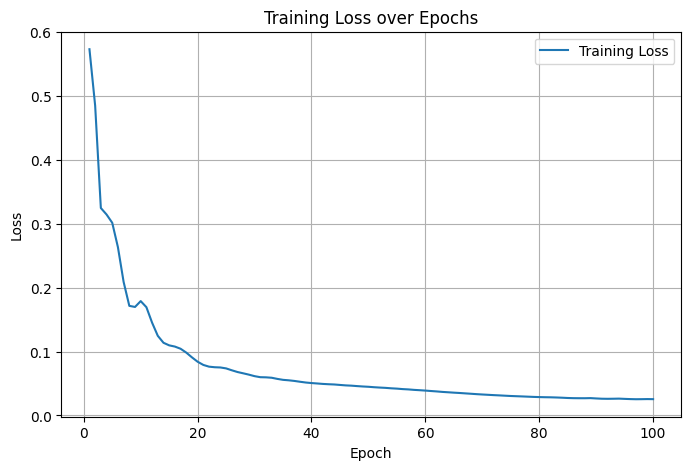

In [18]:
Path("images").mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 5))
plt.plot(MLP_MODEL_epoch_log, MLP_MODEL_loss_log, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.legend()
plt.grid(True)
plt.savefig('images/Training_Loss_over_Epochs.png', dpi=300, bbox_inches='tight')
plt.show()

### Evaluate Model

In [19]:
valid_loss, valid_probs, valid_labels = evaluate(MLP_MODEL, valid_loader)
train_loss, train_probs, train_labels = evaluate(MLP_MODEL, train_loader)

valid_preds = (valid_probs >= 0.5).astype(int)

cm = confusion_matrix(valid_labels, valid_preds)

print(f"Train loss {train_loss:.4f} | Valid loss {valid_loss:.4f}")
print(f"Valid ROC AUC: {roc_auc_score(valid_labels, valid_probs):.3f}")
print(classification_report(valid_labels, valid_preds, digits=3))
print(cm)

Train loss 0.0255 | Valid loss 0.1655
Valid ROC AUC: 0.957
              precision    recall  f1-score   support

           0      0.986     0.932     0.959     13892
           1      0.579     0.876     0.697      1475

    accuracy                          0.927     15367
   macro avg      0.783     0.904     0.828     15367
weighted avg      0.947     0.927     0.933     15367

[[12954   938]
 [  183  1292]]


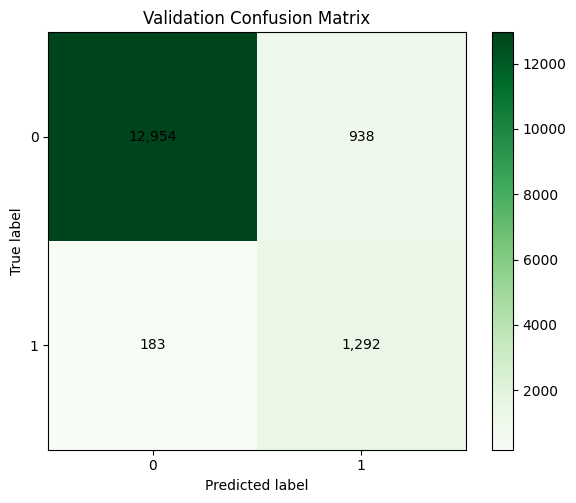

In [20]:
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(cm, cmap="Greens")
fig.colorbar(image, ax=ax)

ax.set(
    xticks=np.arange(2),
    yticks=np.arange(2),
    xticklabels=["0", "1"],
    yticklabels=["0", "1"],
    xlabel="Predicted label",
    ylabel="True label",
    title="Validation Confusion Matrix",
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")

plt.tight_layout()
plt.savefig('images/Validation_Confusion_Matrix.png', dpi=300, bbox_inches='tight')
plt.show()

#### Checkpoint: 11/12/2026
```
EPOCH        = 50
Batch        = 512
lr           = 1e-3
weight_decay = 1e-3
```
|   | 0 | 1 |
|---|---:|---:|
| 0 | 12501 | 1391 |
| 1 | 220 | 1255 |

```
EPOCH        = 50
Batch        = 512
lr           = 1e-2
weight_decay = 1e-3
```
|   | 0 | 1 |
|---|---:|---:|
| 0 | 12036 | 1856 |
| 1 | 108 | 1367 |

```
EPOCH        = 100
Batch        = 512
lr           = 1e-2
weight_decay = 1e-3
```
|   | 0 | 1 |
|---|---:|---:|
| 0 | 12596 | 1296 |
| 1 | 168 | 1307 |

```
EPOCH        = 100
Batch        = 512
lr           = 1e-2
weight_decay = 1e-2
```
|   | 0 | 1 |
|---|---:|---:|
| 0 | 11175 | 2717 |
| 1 | 171 | 1304 |
```
EPOCH        = 100
Batch        = Full
lr           = 1e-2
weight_decay = 1e-2
```
|   | 0 | 1 |
|---|---:|---:|
| 0 | 12954 | 938 |
| 1 | 183 | 1292 |

```